**Imports** Run the model from t=0 upto t=20 by using different beta values

In [ ]:
!py simulate_abm.py --num-infected 30 --num-steps 7 --gamma 7 \
  --beta-start 0.0 --beta-step 0.1 --beta-count 70 \
  --tau 0 --runs 20 --out abm_bank_all_okinawa_cases_test_7.npz 

Simulated agent spread by using an ABM,
Visualized infection states on a grid, 
Calculated  distances of the infected agents from the center,
plotted the distance distribution.

**Difference in the number of infected in simulated and obs**

Estimates β by comparing the simulated number of infected agents at step 20 with the observed infected from the CSV, selecting the β with the smallest difference. 

Compares simulated and observed radious distance distributions of infected agents from the grid center for different β values.

Runs simulations for each β and plots histograms of infected distances.

Plots the observed distance distribution from CSV data.

Computes the difference between simulated and observed distributions to estimate the β with the closest match.

Combine all beta estimations methods in line plots

Plotting by using the new particle_filter.p file 

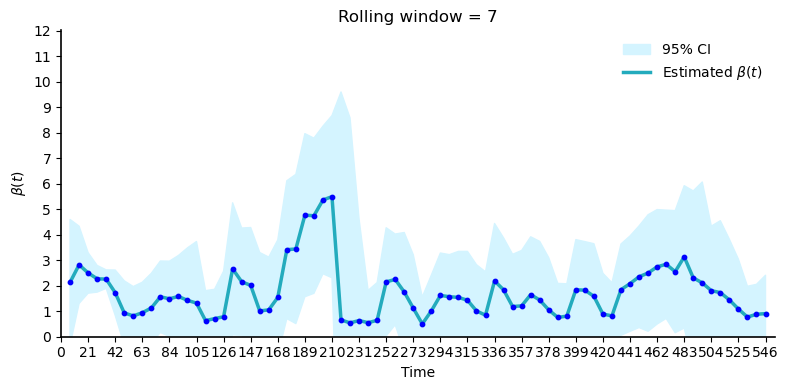

In [1]:
import os
import numpy as np
from particle_filter_abm_c_dist import (
    run_simulations,
    plot_half,
    get_all_simulations,
    plot_all_runs, 
    plot_mean_betas,
    plot_all_vs_half,
    plot_mean_betas,
    export_mean_betas_to_csv,
    plot_all_vs_half_recomputed_distance
)

simulation_data = "abm_bank_all_okinawa_cases_test_7.npz"
obs = "influenza_prefecture_daily_2024_2025.csv"


t_start = 7
t_final = 546
window  = 7

os.makedirs(f"figsc_negative_okinawa_cases_test_7", exist_ok=True)

#run_simulations(
#    observed_csv=obs,
#    bank_path=simulation_data,
#    t_start=t_start, t_final=t_final, window=window,
#    run_replicates=2, gamma=7,
#    append_back_to_bank=True,
#    beta_start=0.0,
#    beta_step=0.1,
#    beta_count=70,
#)



beta_xlim  = (0.0, 12.01)
beta_xtick = np.arange(0.0, 12.001, 1.0)

#for t in range(t_start, t_final + 1, window):
#    
#    plot_half(
#        simulation_data,
#        t=t,
#        title=f"Lower half at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figsc_okinawa_cases_test/lower_half_t{t}.pdf",
#        show=False,
#        close=True
#    )    

#for t in range(t_start + window, t_final + 1, window):
#    
#    bC_all, dC_all = get_all_simulations(simulation_data, t=t)
#    plot_all_runs(
#        betas_C=bC_all, dC=dC_all,
#        title=f"All runs at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figsc_okinawa_cases_test/all_runs_t{t/7}.pdf",
#        show=False,
#        close=True
#    )


time_xlim  = (0, t_final+window)
time_xtick = np.arange(0, t_final+1,  3 * window) 


#for t in range(t_start + window, t_final + 1, window):
#    plot_all_vs_half(
#        bank_path=simulation_data,
#        t=t,
#        title=f"All runs at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figsc_niigata_cases_test/all_vs_half_t{t/7}.png",
#        show=False,
#        close=True,
#    )

for t in range(t_start + window, t_final + 1, window):
    plot_all_vs_half_recomputed_distance(
        bank_path=simulation_data,
        observed_csv=obs,
        t=t,
        title=f"Selected and unselected particles at week {t/7}",
        xlim=beta_xlim,
        xtick=beta_xtick,
        save_path=rf"figsc_negative_okinawa_cases_test_7/all_vs_half_t{t//7}.png", #figsc_negative_dist_okinawa_cases_test_7
        show=False,
        close=True,
    )

plot_mean_betas(
    bank_path=simulation_data,
    title=f'Rolling window = {window}',
    overlay_csv_path="influenza_prefecture_daily_2024_2025.csv",         
    save_path=f"figsc_okinawa_cases_test_7/ABL_{window}.png",
    xlim=time_xlim,
    ylim=beta_xlim, 
    xtick=time_xtick,
    ytick=beta_xtick,
    show=True,
    close=True
)


export_mean_betas_to_csv(
    bank_path=simulation_data,
    out_csv=f"estimated_transmission_okinawa_7.csv",
)


In [ ]:
!py particle_filter_abm_c_dist_inf_plot.py \
  --bank-path abm_bank_all_fukui_cases_test_7.npz \
  --t-max 546 \
  --mode over_time \
  --observed-csv influenza_prefecture_daily_2024_2025.csv \
  --save figsc_fukui_cases_test_7/selected_infected_fukui_cases_2024_2025.pdf
 # --title "Observed infected and particle filter simulated infected over time" 
# now okinawa error 2.57 % kyoto = 8.67%, for fukui 47.94% niigata 25.5%

Using previous weight

In [ ]:
!py particle_filter_abm_c_dist_inf_prev_plot.py \
  --bank-path abm_bank_all_okinawa_cases_test.npz \
  --t-max 546 \
  --mode over_time \
  --observed-csv influenza_prefecture_daily_2024_2025.csv \
  --save figsc_okinawa_cases_20204_2025_prev/selected_infected_okinawa_cases_20204_2025_prev.pdf
 # --title "Observed infected and particle filter simulated infected over time" 


!py particle_filter_abm_c_dist_inf_prev_plot.py \
  --bank-path abm_bank_all_okinawa_cases_test.npz \
  --t-max 546 \
  --mode week_combined \
  --observed-csv influenza_prefecture_daily_2024_2025.csv \
  --save igsc_okinawa_cases_20204_2025_prev/selected_infected_okinawa_cases_20204_2025_prev.pdf

In [ ]:
!py particle_filter_abm_c_dist_inf_prev_plot.py \
  --bank-path abm_bank_all_kyoto_cases_test_7.npz \
  --t-max 546 \
  --mode week_combined \
  --observed-csv influenza_prefecture_daily_2024_2025.csv \
  --save igsc_kyoto_cases_20204_2025_prev_7/selected_infected_kyoto_cases_20204_2025_forcast.pdf
  


In [ ]:
import numpy as np
from Beta_plots import plot_mean_betas_multi

t_final = 547


Pref = [1, 2, 3, 4]



BANKS = {
    1: "abm_bank_all_okinawa_cases_test_7.npz",
    2: "abm_bank_all_niigata_cases_test_7.npz",
    3: "abm_bank_all_kyoto_cases_test_7.npz",
    4:  "abm_bank_all_fukui_cases_test_7.npz",
    #5: "abm_bank_all_iwate_cases_2024_2025.npz",
    #6: "abm_bank_all_aomori_cases_2024_2025.npz",
}

COLORS = {
    1:  "blue",
    2: "blue",
    3: "blue",
    4: "blue",
    #5: "blue",
    #6: "blue",
}

COLORSd = {
    1:  "skyblue",
    2: "skyblue",
    3: "skyblue",
    4: "skyblue",
    #5: "skyblue",
    #6: "skyblue",
}

LinwCOLORS = {
    1:  "black",
    2: "black",
    3: "black",
    4: "black",
    #5: "black",
    #6: "black",
}

SELECT = [1, 2, 3, 4] 
Labels = ["Okinawa", "Niigata", "Kyoto", "Fukui"]     

plot_mean_betas_multi(
    bank_paths=[BANKS[w] for w in SELECT],
    labels=[f"{w}" for w in Labels],
    save_path="figs_multi/estimated_beta.pdf",
    xlim=[(0,551),(0,551),(0,551), (0, 551)],   
    ylim=[(0,12.01),(0,12.01),(0,12.01), (0,12.01)],   
    xtick=np.arange(0, 561, 28),
    ytick=np.arange(0.0, 12.01, 2.0),
    line_colors=[COLORS[w] for w in SELECT],
    lines_colors=[LinwCOLORS[w] for w in SELECT],
    lined_colors=[COLORSd[w] for w in SELECT],
    line_alphas=[1.0 for _ in SELECT],
    ci_colors=[COLORS[w] for w in SELECT],
    ci_alphas=[0.5 for _ in SELECT],
    ncols=2,  
)


In [ ]:
import betaplot

betaplot.plot_beta(
    "estimated_transmission_fukui_7.csv",
    obs_csv="influenza_prefecture_daily_2024_2025.csv",
    obs_col="fukui_cases",
    title="Fukui",
    save_path="figs_multi/estimated_transmission_fukui.pdf"
)

Previous weights sum: 1.0
Previous time: 154


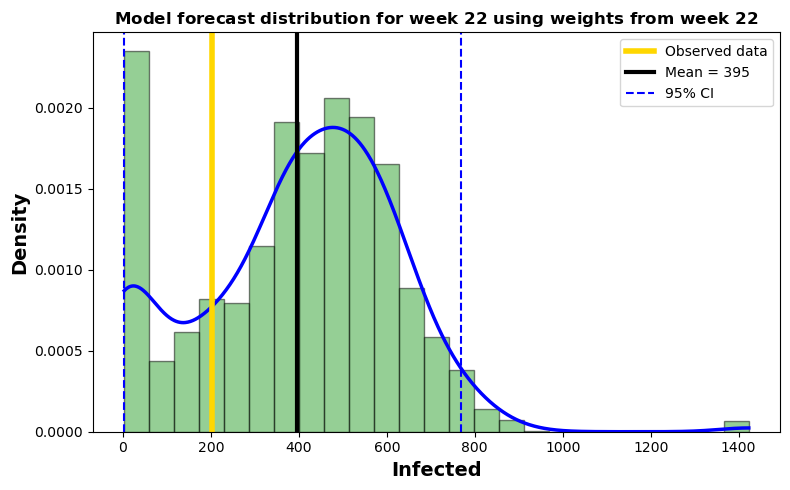

Current weights sum: 1.0000000000000002


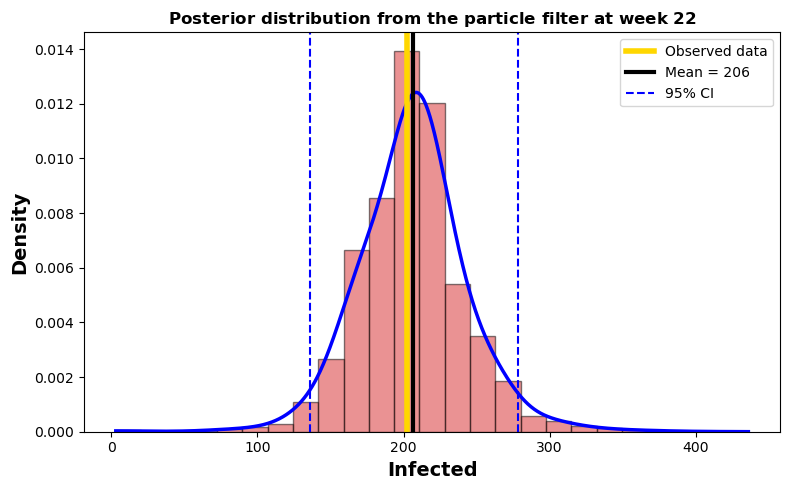

In [1]:
import numpy as np
from Infected_plots import plot_infected_with_previous_weights, plot_infected_posterior_at_time

plot_infected_with_previous_weights(
    bank_path="abm_bank_all_okinawa_cases_test_7.npz",
    time_point=22*7,
    observed_csv_path = "influenza_prefecture_daily_2024_2025.csv",
    save_path="figs_multi/posterior_forcats_okinawa.pdf",
)


plot_infected_posterior_at_time(
    bank_path="abm_bank_all_okinawa_cases_test_7.npz",
    time_point=22*7,
    observed_csv_path = "influenza_prefecture_daily_2024_2025.csv",
    save_path="figs_multi/Posterior_estimated_okinawa.pdf",
)